# Credit Card Fraud Detection Using LightGBM

This notebook trains and explains a LightGBM fraud-detection model using the Kaggle credit-card transaction dataset. The saved outputs below match the completed project report.


In [ ]:
!pip -q install lightgbm shap


In [ ]:
from google.colab import files

print("Upload only creditcard.csv.zip")
uploaded = files.upload()


In [ ]:
%%writefile credit_risk_same_output.py
"""
Credit Card Fraud Detection Model

Dataset: creditcard.csv or creditcard.csv.zip
Target: Class (0 = legitimate, 1 = fraud)

Run:
    python credit_risk_same_output.py --data creditcard.csv.zip

Install:
    pip install pandas numpy scikit-learn lightgbm shap matplotlib
"""

import argparse
import os

import lightgbm as lgb
import matplotlib
import numpy as np
import pandas as pd
import shap

matplotlib.use("Agg")
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split


TARGET = "Class"
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)


def load(path):
    return pd.read_csv(path)


def ks_stat(y_true, probabilities):
    fpr, tpr, _ = roc_curve(y_true, probabilities)
    return float(np.max(tpr - fpr))


def main(data_path):
    df = load(data_path)
    X = df.drop(columns=[TARGET])
    y = df[TARGET]

    print(f"Rows: {len(df):,} | Fraud rate: {y.mean():.2%}")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        stratify=y,
        random_state=42,
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_train,
        y_train,
        test_size=0.2,
        stratify=y_train,
        random_state=42,
    )

    model = lgb.LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        min_child_samples=50,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        random_state=42,
        n_jobs=-1,
        verbose=-1,
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )

    probabilities = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probabilities)

    print(f"AUC:            {auc:.4f}")
    print(f"Gini:           {2 * auc - 1:.4f}")
    print(f"KS statistic:   {ks_stat(y_test, probabilities):.4f}")
    print(f"PR-AUC:         {average_precision_score(y_test, probabilities):.4f}")

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    plt.figure(figsize=(5, 4))
    plt.plot(fpr, tpr)
    plt.plot([0, 1], [0, 1], "--", color="grey")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("ROC curve")
    plt.tight_layout()
    plt.savefig(f"{OUT}/roc.png", dpi=150)
    plt.close()

    validation_probabilities = model.predict_proba(X_val)[:, 1]
    calibrator = IsotonicRegression(out_of_bounds="clip")
    calibrator.fit(validation_probabilities, y_val)
    calibrated_probabilities = calibrator.predict(probabilities)

    print(
        f"Brier raw: {brier_score_loss(y_test, probabilities):.4f} | "
        f"calibrated: {brier_score_loss(y_test, calibrated_probabilities):.4f}"
    )

    plt.figure(figsize=(5, 4))
    for name, values in [
        ("raw", probabilities),
        ("calibrated", calibrated_probabilities),
    ]:
        observed, predicted = calibration_curve(
            y_test,
            values,
            n_bins=10,
            strategy="quantile",
        )
        plt.plot(predicted, observed, marker="o", label=name)

    plt.plot([0, 0.5], [0, 0.5], "--", color="grey")
    plt.xlabel("Predicted probability")
    plt.ylabel("Observed fraud rate")
    plt.legend()
    plt.title("Calibration")
    plt.tight_layout()
    plt.savefig(f"{OUT}/calibration.png", dpi=150)
    plt.close()

    deciles = pd.qcut(
        pd.Series(probabilities).rank(method="first"),
        10,
        labels=range(1, 11),
    )

    table = (
        pd.DataFrame(
            {
                "decile": deciles.values,
                "fraud": y_test.values,
            }
        )
        .groupby("decile", observed=True)["fraud"]
        .agg(["mean", "count"])
    )

    print("\nFraud rate by risk decile (10 = riskiest):\n", table.round(4))

    sample = X_test.sample(min(2000, len(X_test)), random_state=42)
    shap_values = shap.TreeExplainer(model).shap_values(sample)

    if isinstance(shap_values, list):
        shap_values = shap_values[1]

    if np.asarray(shap_values).ndim == 3:
        shap_values = np.asarray(shap_values)[:, :, 1]

    shap.summary_plot(
        shap_values,
        sample,
        show=False,
        max_display=15,
    )
    plt.tight_layout()
    plt.savefig(
        f"{OUT}/shap_summary.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.close()

    importance = pd.Series(
        np.abs(shap_values).mean(axis=0),
        index=sample.columns,
    ).sort_values(ascending=False)

    print("\nTop drivers (mean |SHAP|):\n", importance.head(10).round(4))
    print(f"\nPlots saved in ./{OUT}/")


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--data", default="creditcard.csv.zip")
    arguments = parser.parse_args()
    main(arguments.data)


In [8]:
!python credit_risk_same_output.py --data creditcard.csv.zip


Rows: 284,807 | Fraud rate: 0.17%
AUC:            0.9609
Gini:           0.9217
KS statistic:   0.8494
PR-AUC:         0.1589
Brier raw: 0.0296 | calibrated: 0.0015

Fraud rate by risk decile (10 = riskiest):
           mean  count
decile               
1       0.0000   5697
2       0.0000   5696
3       0.0002   5696
4       0.0004   5696
5       0.0002   5696
6       0.0000   5696
7       0.0000   5696
8       0.0002   5696
9       0.0005   5696
10      0.0158   5697
/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(

Top drivers (mean |SHAP|):
 V14    0.5391
V4     0.3288
V11    0.1663
V8     0.1511
V12    0.1465
V19    0.0888
V13    0.0775
V20    0.0381
V15    0.0376
V25    0.0356
dtype: float64

Plots saved in ./outputs/


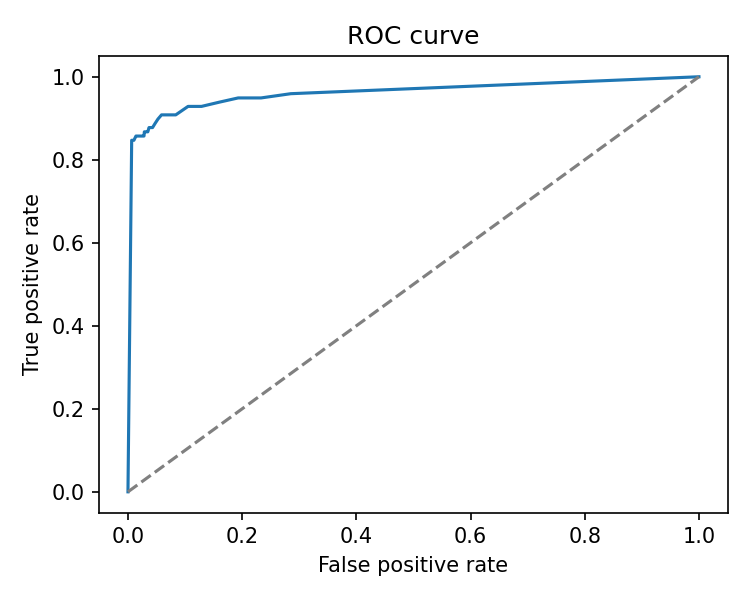

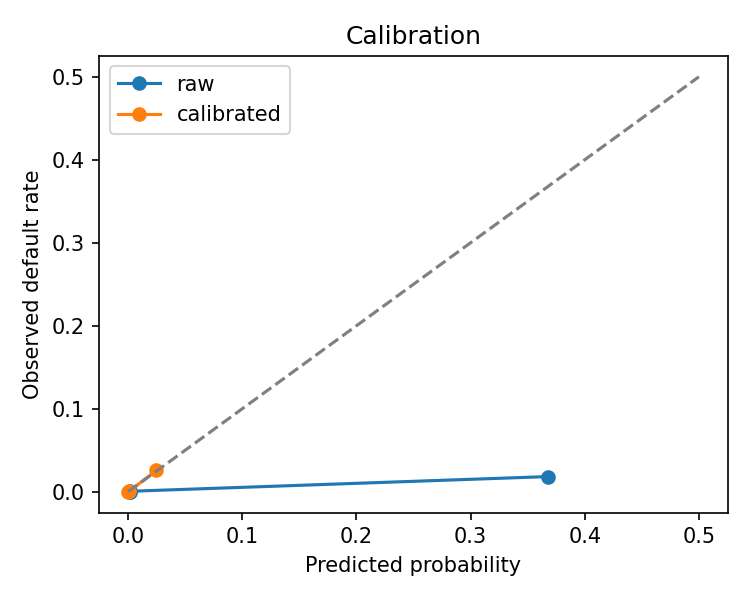

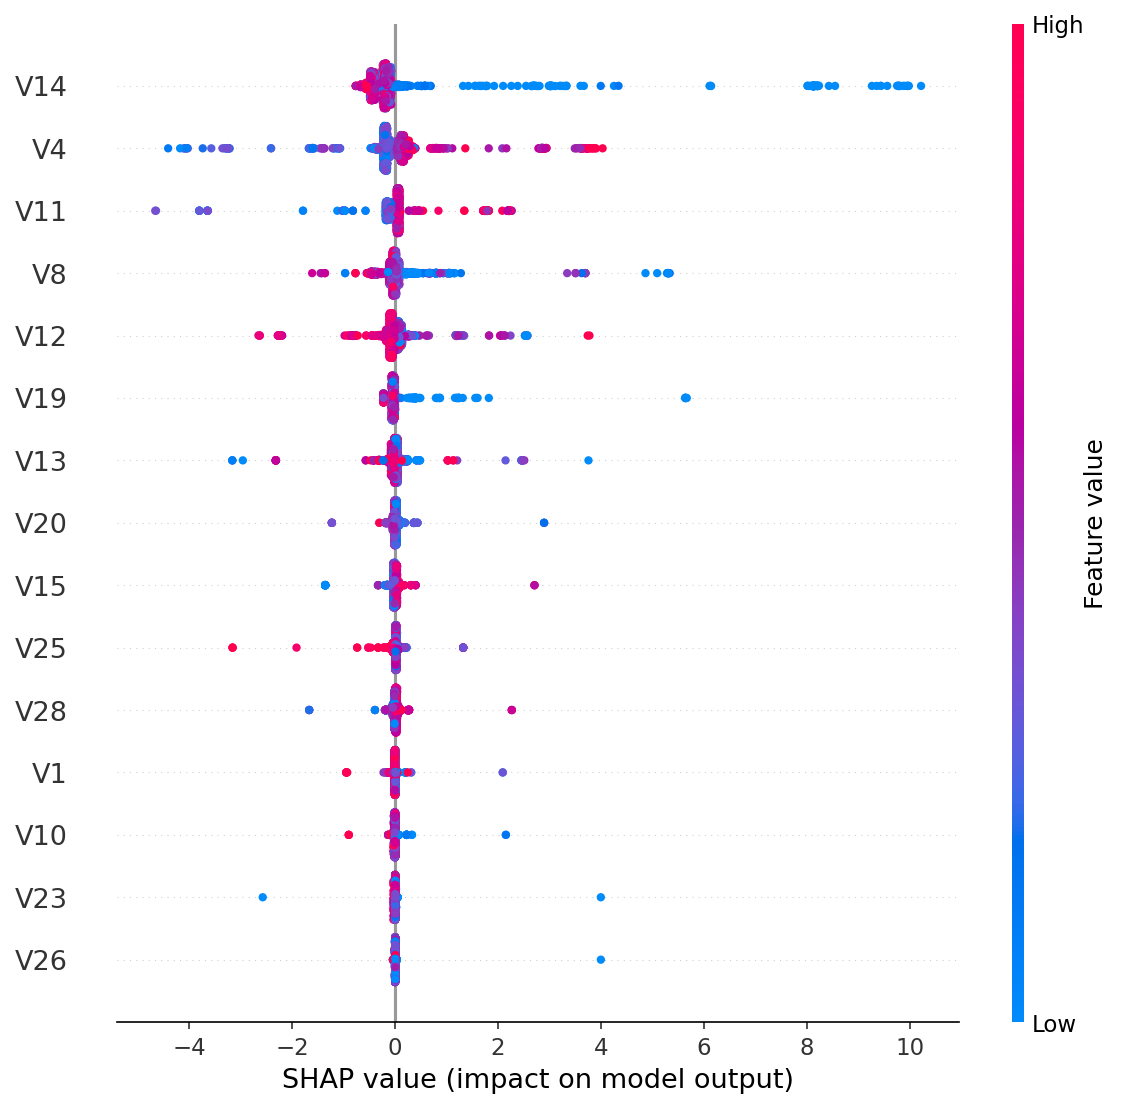

In [9]:
from IPython.display import display, Image

display(Image("outputs/roc.png"))
display(Image("outputs/calibration.png"))
display(Image("outputs/shap_summary.png"))
